In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report


In [ ]:
data = pd.read_csv("/content/student_data.csv")
print(data)

    age  studyhours  attendance  previousmarks  assignmentscore result
0    17         5.5        88.0           76.0             82.0   Pass
1    18         2.0        60.0            NaN             55.0   Fail
2    16         7.0        95.0           89.0             91.0   Pass
3    19         NaN        72.0           68.0              NaN   Pass
4    17         1.5        45.0           40.0             38.0   Fail
5    18         6.0         NaN           85.0             88.0   Pass
6    16         3.0        55.0           50.0              NaN   Fail
7    20         8.0        92.0           95.0             97.0   Pass
8    17         4.5         NaN           72.0             75.0   Pass
9    19         0.5        30.0            NaN             20.0   Fail
10   18         5.0        80.0            NaN             79.0   Pass
11   16         NaN        65.0           60.0             58.0   Fail
12   17         6.5        90.0           84.0              NaN   Pass
13   2

In [ ]:
print(data.columns)

Index(['age', 'studyhours', 'attendance', 'previousmarks', 'assignmentscore',
       'result'],
      dtype='object')


In [ ]:
print(data.dtypes)

age                  int64
studyhours         float64
attendance         float64
previousmarks      float64
assignmentscore    float64
result              object
dtype: object


In [ ]:
print(data.describe())

             age  studyhours  attendance  previousmarks  assignmentscore
count  15.000000   13.000000   12.000000      12.000000        12.000000
mean   17.800000    4.576923   68.500000      71.166667        68.166667
std     1.373213    2.456676   21.073465      18.731759        25.062951
min    16.000000    0.500000   30.000000      40.000000        20.000000
25%    17.000000    2.500000   53.750000      57.500000        51.750000
50%    18.000000    5.000000   68.500000      74.000000        77.000000
75%    19.000000    6.500000   88.500000      86.000000        88.750000
max    20.000000    8.000000   95.000000      95.000000        97.000000


In [ ]:
print(data.duplicated().sum())

0


In [ ]:
data["studyhours"] = data["studyhours"].fillna(data["studyhours"].mean())
data["attendance"] = data["attendance"].fillna(data["attendance"].mean())
data["previousmarks"] = data["previousmarks"].fillna(data["previousmarks"].mean())
data["assignmentscore"] = data["assignmentscore"].fillna(data["assignmentscore"].mean())
print(data.isnull().sum())
print(data)

age                0
studyhours         0
attendance         0
previousmarks      0
assignmentscore    0
result             0
dtype: int64
    age  studyhours  attendance  previousmarks  assignmentscore result
0    17    5.500000        88.0      76.000000        82.000000   Pass
1    18    2.000000        60.0      71.166667        55.000000   Fail
2    16    7.000000        95.0      89.000000        91.000000   Pass
3    19    4.576923        72.0      68.000000        68.166667   Pass
4    17    1.500000        45.0      40.000000        38.000000   Fail
5    18    6.000000        68.5      85.000000        88.000000   Pass
6    16    3.000000        55.0      50.000000        68.166667   Fail
7    20    8.000000        92.0      95.000000        97.000000   Pass
8    17    4.500000        68.5      72.000000        75.000000   Pass
9    19    0.500000        30.0      71.166667        20.000000   Fail
10   18    5.000000        80.0      71.166667        79.000000   Pass
11   16  

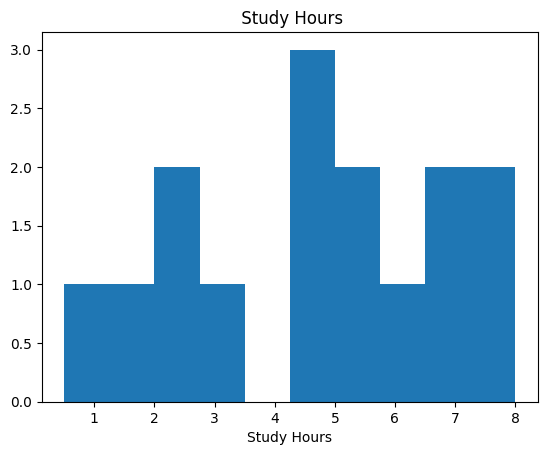

In [ ]:
plt.hist(data["studyhours"])
plt.xlabel("Study Hours")
plt.title(" Study Hours")
plt.show()

In [ ]:
data["performancescore"] = (0.3 * data["previousmarks"] +
                            0.2 * data["studyhours"] +
                            0.25 * data["attendance"] +
                            0.25 * data["assignmentscore"])

display(data.head())

,age,studyhours,attendance,previousmarks,assignmentscore,result,performancescore
0,17,5.500000,88.0,76.000000,82.000000,Pass,66.400000
1,18,2.000000,60.0,71.166667,55.000000,Fail,50.500000
2,16,7.000000,95.0,89.000000,91.000000,Pass,74.600000
3,19,4.576923,72.0,68.000000,68.166667,Pass,56.357051
4,17,1.500000,45.0,40.000000,38.000000,Fail,33.050000


In [ ]:
X = data[["studyhours", "attendance", "previousmarks", "assignmentscore", "performancescore"]]
y = data["result"]

print(y)

0     Pass
1     Fail
2     Pass
3     Pass
4     Fail
5     Pass
6     Fail
7     Pass
8     Pass
9     Fail
10    Pass
11    Fail
12    Pass
13    Fail
14    Pass
Name: result, dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42
)


In [ ]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred)

['Fail' 'Pass' 'Pass']


In [ ]:
result = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(result)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
precision = precision_score(y_test, y_pred, pos_label='Pass')
print("Precision:", precision)

   Actual Predicted
9    Fail      Fail
11   Fail      Pass
0    Pass      Pass
Accuracy: 0.6666666666666666
Precision: 0.5
